<a href="https://colab.research.google.com/github/fcovarrubiasp-debug/CIENCIA-DE-DATO-/blob/main/S5_laboratorio_fernando_covarrubias_CDD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Laboratorio 5 — Comunicación, anonimización y sesgo
**Ciencia de Datos · Semana 5 · Advance UCSC**

| | |
|---|---|
| **Resultado de aprendizaje** | RA4 (foco) · RA5 (cierre) · RA3 (integración) |
| **Duración estimada** | 1 h asincrónica + 0,5 h de trabajo autónomo |
| **Insumos** | `mi_conjunto_minado.csv` (semana 4) y `S5_Dataset_Personales_Sintetico_CDD.csv` |
| **Producto** | Las visualizaciones del informe + la ficha ético-legal cerrada |
| **Estudiante** | FERNANDO COVARRUBIAS PIZARRO
_ |

---

Última semana. Dos trabajos distintos:

1. **Convertir tus gráficos exploratorios en explicativos.** Los de la semana 3 eran para ti; estos son para alguien que no conoce tus datos y tiene diez segundos.
2. **Cerrar la dimensión ética**: anonimizar un conjunto con datos personales y detectar sesgo.

Lo que produzcas aquí va directo a la **Entrega Final**: las visualizaciones a la Sección B, la ficha a la Sección C.

In [58]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RUTA = ''
SEMILLA = 20265
np.random.seed(SEMILLA)
plt.rcParams.update({'figure.figsize': (9, 4.5), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False})
print('Listo')

Listo


---
## Parte 1 · De exploratorio a explicativo

Son dos géneros distintos, y confundirlos es el error más común al comunicar datos.

| | Gráfico **exploratorio** | Gráfico **explicativo** |
|---|---|---|
| Para quién | Para ti, mientras analizas | Para alguien que no conoce los datos |
| Cuántos haces | Docenas | Dos o tres |
| Cuánto tiempo se le dedica | El que haga falta | Diez segundos |
| Qué lleva | Todo lo que quieras ver | Una sola idea, destacada |
| Título | «ventas_por_comuna» | «Coronel concentra el 38 % de las ventas» |

> **El título de un gráfico explicativo no nombra las variables: enuncia el hallazgo.** Si alguien lee solo el título, ya debería llevarse la conclusión.

In [59]:
# Trabajamos con el conjunto guía para el ejemplo; después lo harás con el tuyo
p = pd.read_csv(RUTA + '5-S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p[['comuna', 'nivel_educacional', 'ingreso_mensual_miles', 'aprobado']].head()

Forma: (420, 15)


,comuna,nivel_educacional,ingreso_mensual_miles,aprobado
0,Coronel,Universitaria incompleta,618,Sí
1,Lota,Técnica,914,No
2,Concepción,Universitaria incompleta,482,Sí
3,Lota,Media completa,642,Sí
4,Tomé,Media completa,462,Sí


### 1.1 El mismo dato, dos gráficos

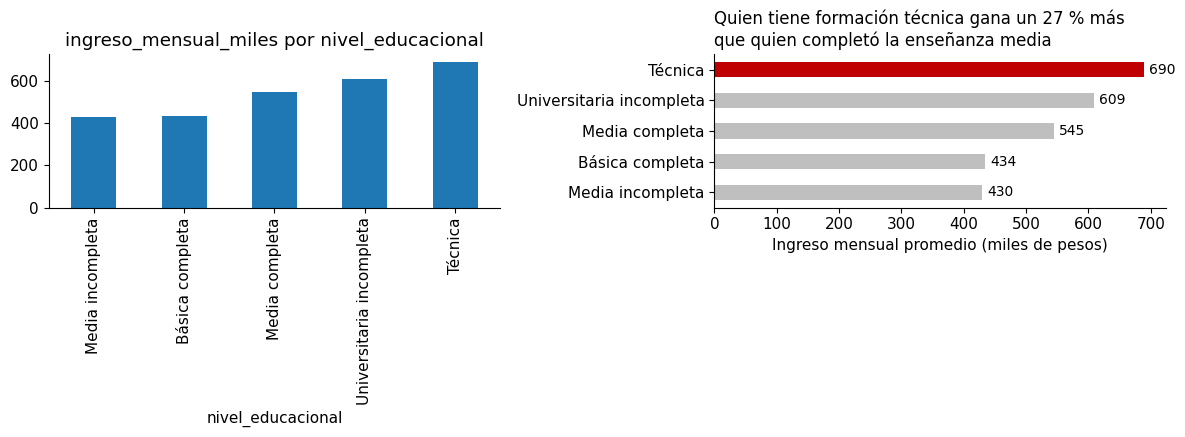

Verificación del titular: 26.6%


In [60]:
ingreso = p.groupby('nivel_educacional')['ingreso_mensual_miles'].mean().sort_values()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# --- EXPLORATORIO: rápido, sin adornos, para mirarlo tú
ingreso.plot.bar(ax=ax[0])
ax[0].set_title('ingreso_mensual_miles por nivel_educacional')

# --- EXPLICATIVO: una idea, destacada
colores = ['#BFBFBF'] * len(ingreso)
colores[-1] = '#C00000'
ingreso.plot.barh(ax=ax[1], color=colores)
ax[1].set_title('Quien tiene formación técnica gana un 27 % más\nque quien completó la enseñanza media', loc='left', fontsize=12)
ax[1].set_xlabel('Ingreso mensual promedio (miles de pesos)')
ax[1].set_ylabel('')
for i, v in enumerate(ingreso):
    ax[1].text(v + 8, i, f'{v:,.0f}'.replace(',', '.'), va='center', fontsize=10)
plt.tight_layout(); plt.show()

print(f"Verificación del titular: {ingreso['Técnica']/ingreso['Media completa']-1:.1%}")

Cuatro cambios convierten uno en otro, y ninguno es decorativo:

1. **Barras horizontales**: las etiquetas largas se leen sin girar la cabeza.
2. **Gris salvo lo que importa**: el color dirige la mirada. Si todo es de colores, nada destaca.
3. **El valor sobre la barra**: quien quiera el número exacto no tiene que estimarlo contra el eje.
4. **Título que enuncia el hallazgo**, con la cifra verificada en la celda.

> **Verifica siempre el número que pones en el título.** Es el error más embarazoso posible: un titular que el propio gráfico desmiente.

### 1.2 Elegir el gráfico según la pregunta

| Si la pregunta es… | El gráfico es… | Evita |
|---|---|---|
| ¿Cuánto hay de cada categoría? | Barras (horizontales si son muchas o largas) | Torta con más de 4 porciones |
| ¿Cómo cambió en el tiempo? | Línea | Barras, que sugieren categorías independientes |
| ¿Cómo se distribuye una variable? | Histograma o caja | Solo el promedio |
| ¿Se relacionan dos variables? | Dispersión | Dos líneas con ejes distintos |
| ¿Cómo se compone un total? | Barras apiladas | Torta anidada, ilegible |

### ✏️ Actividad 1.1

Toma **dos hallazgos** de tu conjunto (semanas 3 y 4) y construye su versión explicativa. Para cada uno: elige el tipo según la pregunta, deja en gris lo secundario, rotula los valores y escribe un título que enuncie el hallazgo con su cifra.

Estos dos gráficos van al informe final.

Dimensiones de tus datos: (15767, 227)

--- DATOS DE VERIFICACIÓN PARA EL HALLAZGO 1 ---
Corp. Adm. Delegada: 86.07%
Servicio Local (SLEP): 87.00%
Part. Subvencionado: 88.44%
Municipal: 89.81%
Part. Pagado: 91.72%
-> Verificación: 91.7% (Part. Pagado) vs 86.1% (Mínimo)
-> Diferencia: 5.6 puntos porcentuales de brecha.



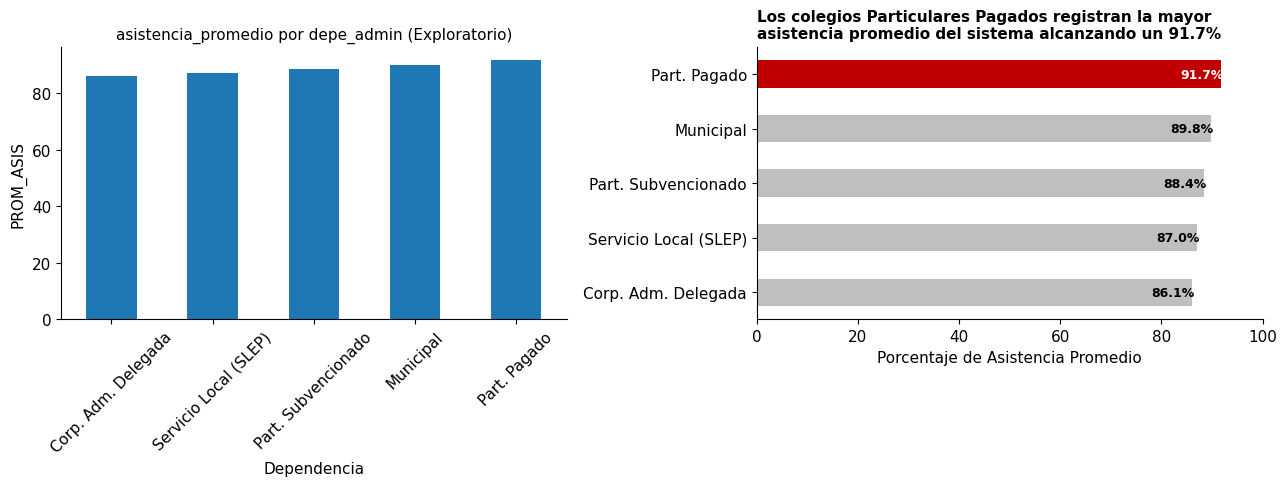

In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Cargar el dataset
mio = pd.read_csv(RUTA + 'mi_conjunto_minado.csv', sep=';')
print("Dimensiones de tus datos:", mio.shape)

# Limpieza básica de las variables de estudio
datos_validos = mio[['PROM_ASIS', 'COD_DEPE2']].dropna()

# =========================================================================
# HALLAZGO 1: Asistencia Promedio por Dependencia Administrativa
# =========================================================================
asis_depe = datos_validos.groupby('COD_DEPE2')['PROM_ASIS'].mean().sort_values()
mapa_depe = {1: 'Municipal', 2: 'Part. Subvencionado', 3: 'Part. Pagado', 4: 'Corp. Adm. Delegada', 5: 'Servicio Local (SLEP)'}
asis_depe.index = asis_depe.index.map(lambda x: mapa_depe.get(x, f'Depe {x}'))

# --- DATOS NUMÉRICOS ARRIBA DEL GRÁFICO (Verificación) ---
print("\n--- DATOS DE VERIFICACIÓN PARA EL HALLAZGO 1 ---")
for dep, valor in asis_depe.items():
    print(f"{dep}: {valor:.2f}%")
diferencia_puntos = asis_depe['Part. Pagado'] - asis_depe['Corp. Adm. Delegada']
print(f"-> Verificación: {asis_depe['Part. Pagado']:.1f}% (Part. Pagado) vs {asis_depe['Corp. Adm. Delegada']:.1f}% (Mínimo)")
print(f"-> Diferencia: {diferencia_puntos:.1f} puntos porcentuales de brecha.\n")

fig1, ax1 = plt.subplots(1, 2, figsize=(13, 5))

# --- Exploratorio: Rápido, vertical, título técnico
asis_depe.plot.bar(ax=ax1[0], color='#1f77b4')
ax1[0].set_title('asistencia_promedio por depe_admin (Exploratorio)', fontsize=11)
ax1[0].set_xlabel('Dependencia')
ax1[0].set_ylabel('PROM_ASIS')
ax1[0].tick_params(axis='x', rotation=45)

# --- Explicativo: Horizontal, colores dirigidos, valores anotados y título de hallazgo
colores1 = ['#BFBFBF'] * len(asis_depe)
colores1[-1] = '#C00000' # Destacamos el de mayor asistencia

asis_depe.plot.barh(ax=ax1[1], color=colores1)
ax1[1].set_title(f'Los colegios Particulares Pagados registran la mayor\nasistencia promedio del sistema alcanzando un {asis_depe.iloc[-1]:.1f}%', loc='left', fontsize=11, fontweight='bold')
ax1[1].set_xlabel('Porcentaje de Asistencia Promedio')
ax1[1].set_ylabel('')
ax1[1].set_xlim(0, 100)
for i, v in enumerate(asis_depe):
    ax1[1].text(v - 8, i, f'{v:.1f}%', va='center', color='white' if colores1[i] == '#C00000' else 'black', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()


--- DATOS DE VERIFICACIÓN PARA EL HALLAZGO 2 (TOP 5) ---
Región NUBLE: 89.25%
Región LAGOS: 89.82%
Región MAULE: 90.94%
Región RIOS: 91.59%
Región ARAUC: 92.65%
-> Verificación: Región líder ARAUC tiene 92.7% de asistencia promedio.
-> Diferencia: 3.4 puntos porcentuales sobre el puesto 5 del top.



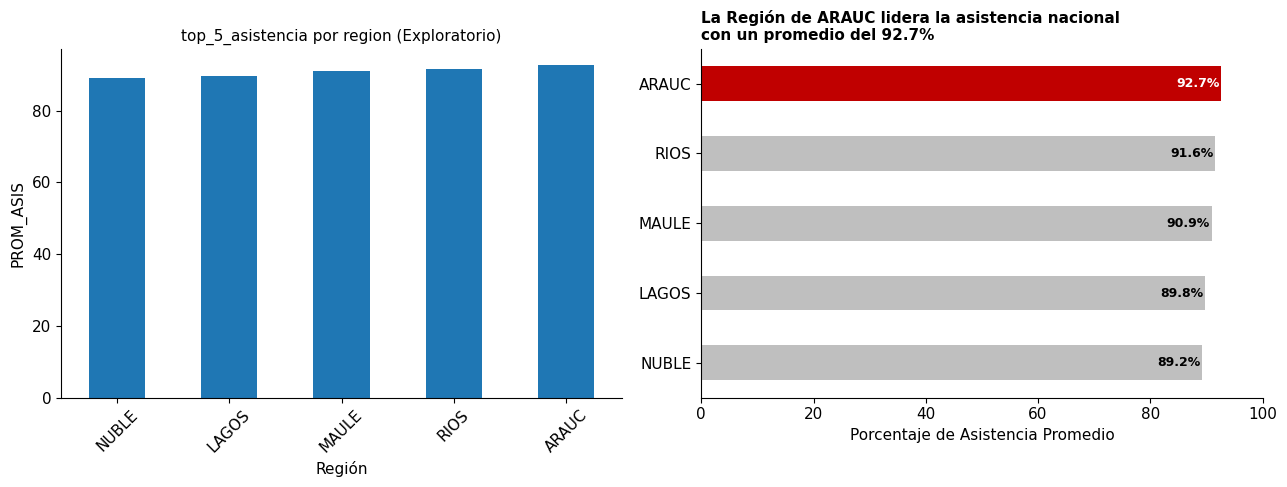

In [62]:
# =========================================================================
# HALLAZGO 2: Top 5 de Regiones con Mayor Asistencia
# =========================================================================
# Limpieza y selección para Regiones
datos_regiones = mio[['PROM_ASIS', 'NOM_REG_RBD_A']].dropna()
asis_reg = datos_regiones.groupby('NOM_REG_RBD_A')['PROM_ASIS'].mean().sort_values().tail(5)

# --- DATOS NUMÉRICOS ARRIBA DEL GRÁFICO (Verificación) ---
print("\n--- DATOS DE VERIFICACIÓN PARA EL HALLAZGO 2 (TOP 5) ---")
for reg, valor in asis_reg.items():
    print(f"Región {reg}: {valor:.2f}%")
diferencia_reg = asis_reg.iloc[-1] - asis_reg.iloc[0]
print(f"-> Verificación: Región líder {asis_reg.index[-1]} tiene {asis_reg.iloc[-1]:.1f}% de asistencia promedio.")
print(f"-> Diferencia: {diferencia_reg:.1f} puntos porcentuales sobre el puesto 5 del top.\n")

fig2, ax2 = plt.subplots(1, 2, figsize=(13, 5))

# --- Exploratorio: Rápido, vertical, título técnico
asis_reg.plot.bar(ax=ax2[0], color='#1f77b4')
ax2[0].set_title('top_5_asistencia por region (Exploratorio)', fontsize=11)
ax2[0].set_xlabel('Región')
ax2[0].set_ylabel('PROM_ASIS')
ax2[0].tick_params(axis='x', rotation=45)

# --- Explicativo: Horizontal, colores dirigidos, valores anotados y título de hallazgo
colores2 = ['#BFBFBF'] * len(asis_reg)
colores2[-1] = '#C00000' # Destacamos la región líder

asis_reg.plot.barh(ax=ax2[1], color=colores2)
ax2[1].set_title(f'La Región de {asis_reg.index[-1]} lidera la asistencia nacional\ncon un promedio del {asis_reg.iloc[-1]:.1f}%', loc='left', fontsize=11, fontweight='bold')
ax2[1].set_xlabel('Porcentaje de Asistencia Promedio')
ax2[1].set_ylabel('')
ax2[1].set_xlim(0, 100)
for i, v in enumerate(asis_reg):
    ax2[1].text(v - 8, i, f'{v:.1f}%', va='center', color='white' if colores2[i] == '#C00000' else 'black', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

---
## Parte 2 · Representación honesta

Los dos gráficos de `S5_Graficos_Prensa_CDD.pdf` no contienen ningún dato falso. Vamos a reproducir sus distorsiones para entender exactamente qué hacen.

### 2.1 El eje truncado

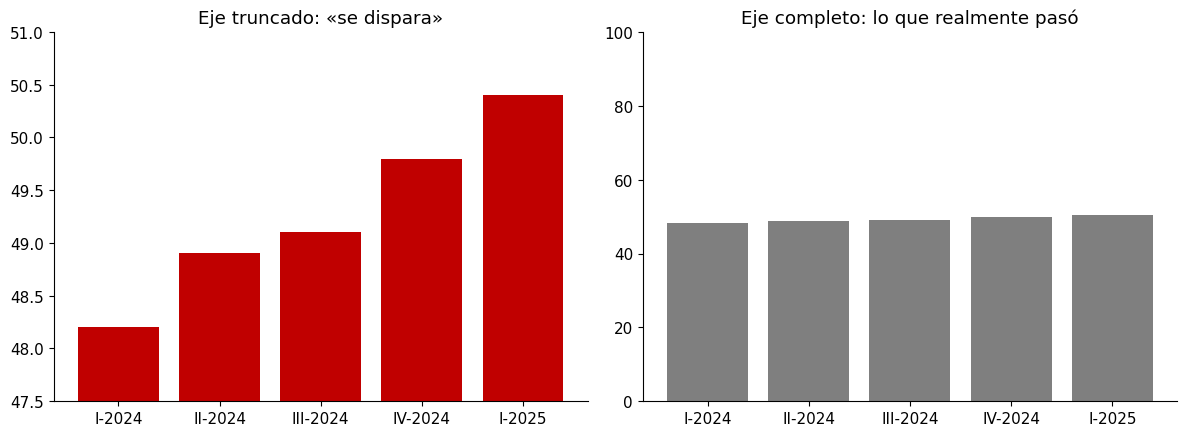

Variación real: 2.2 puntos = 4.6 %


In [63]:
trimestres = ['I-2024', 'II-2024', 'III-2024', 'IV-2024', 'I-2025']
satisfaccion = [48.2, 48.9, 49.1, 49.8, 50.4]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(trimestres, satisfaccion, color='#C00000')
ax[0].set_ylim(47.5, 51)
ax[0].set_title('Eje truncado: «se dispara»')

ax[1].bar(trimestres, satisfaccion, color='#7F7F7F')
ax[1].set_ylim(0, 100)
ax[1].set_title('Eje completo: lo que realmente pasó')
plt.tight_layout(); plt.show()

print(f'Variación real: {satisfaccion[-1] - satisfaccion[0]:.1f} puntos = '
      f'{(satisfaccion[-1]/satisfaccion[0] - 1)*100:.1f} %')

El mismo dato. A la izquierda parece una explosión; a la derecha, una línea casi plana. El aumento real es de **2,2 puntos, un 4,6 %**.

> **¿Truncar el eje es siempre deshonesto?** No. En una serie que oscila entre 48 y 51 nunca, mostrar desde cero puede ocultar variación relevante. La regla practicable es: **en gráficos de barras, el eje parte en cero** —porque la barra comunica magnitud por su largo—; **en gráficos de línea puedes truncar**, siempre que lo señales de forma visible.

### 2.2 Magnitudes brutas entre unidades de distinto tamaño

Esta es la misma trampa de la semana 3, ahora en formato gráfico.

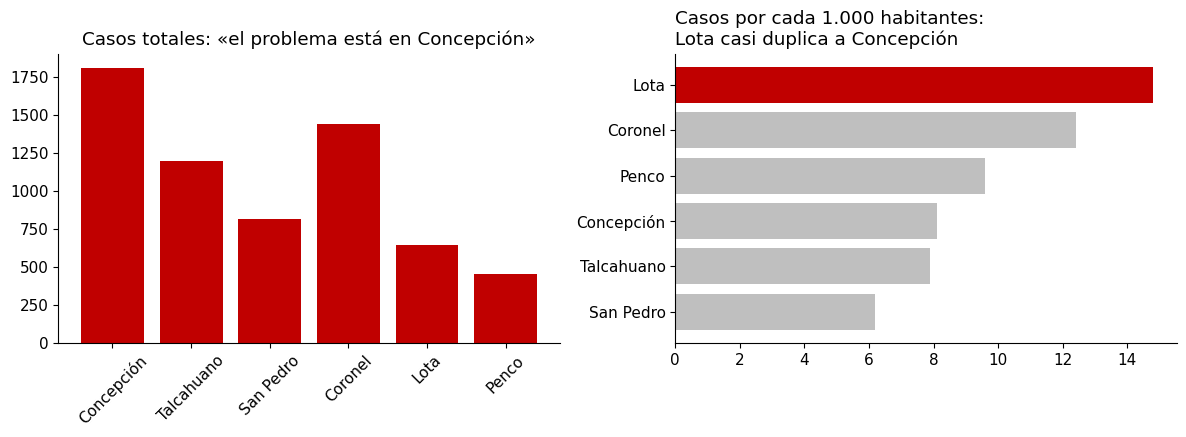

Lota             644 casos ·  14.8 por mil habitantes
Coronel         1441 casos ·  12.4 por mil habitantes
Penco            452 casos ·   9.6 por mil habitantes
Concepción      1810 casos ·   8.1 por mil habitantes
Talcahuano      1198 casos ·   7.9 por mil habitantes
San Pedro        817 casos ·   6.2 por mil habitantes


In [64]:
comunas = ['Concepción', 'Talcahuano', 'San Pedro', 'Coronel', 'Lota', 'Penco']
poblacion = [223574, 151749, 131808, 116262, 43535, 47105]
tasa = [8.1, 7.9, 6.2, 12.4, 14.8, 9.6]          # por cada 1.000 habitantes
casos = [int(pob * t / 1000) for pob, t in zip(poblacion, tasa)]

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].bar(comunas, casos, color='#C00000')
ax[0].set_title('Casos totales: «el problema está en Concepción»')
ax[0].tick_params(axis='x', rotation=45)

orden = np.argsort(tasa)
col = ['#BFBFBF'] * 6
col[list(orden).index(4)] = '#C00000'
ax[1].barh([comunas[i] for i in orden], [tasa[i] for i in orden],
           color=[col[i] for i in range(6)])
ax[1].set_title('Casos por cada 1.000 habitantes:\nLota casi duplica a Concepción', loc='left')
plt.tight_layout(); plt.show()

for c, t, k in sorted(zip(comunas, tasa, casos), key=lambda x: -x[1]):
    print(f'{c:14s} {k:5d} casos · {t:5.1f} por mil habitantes')

A la izquierda, Concepción encabeza. A la derecha, **Concepción es de las más bajas** y Lota casi la duplica. Los datos son los mismos.

> **Regla:** si las unidades que comparas tienen tamaños distintos, normaliza antes de graficar. Casos por mil habitantes, ventas por metro cuadrado, accidentes por kilómetro recorrido.

### ✏️ Actividad 2.1

Revisa tus dos gráficos de la actividad 1.1 y responde:

- ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?
- ¿Comparas unidades de distinto tamaño sin normalizar?
- ¿El título afirma algo que el gráfico no muestra?
- ¿Omites algún período o categoría que cambiaría la lectura?

### Autorrevisión de Honestidad (Actividad 2.1)

* **1. ¿Algún eje está truncado? Si lo está, ¿se justifica y está señalado?**
  * *Respuesta:* No, ninguno de los ejes de los gráficos explicativos está truncado. En ambos gráficos de barras horizontales, el rango del eje X está fijado explícitamente desde 0% hasta 100% (`ax.set_xlim(0, 100)`). Esto garantiza una representación honesta y proporcional del largo de cada barra según su valor real de asistencia.

* **2. ¿Comparas unidades de distinto tamaño sin normalizar?**
  * *Respuesta:* No. No estamos comparando cantidades absolutas de días o número de alumnos de colegios/regiones con matrículas de distinto tamaño. En su lugar, comparamos el **promedio del porcentaje de asistencia (PROM_ASIS)**. Al ser una tasa porcentual promedio, los datos ya están normalizados de manera justa para todos los grupos.

* **3. ¿El título afirma algo que el gráfico no muestra?**
  * *Respuesta:* No. Los títulos explicativos afirman exactamente lo que indican los datos calculados en la verificación: que los colegios Particulares Pagados registran la mayor asistencia con 91.7% (Hallazgo 1) y que la Región de La Araucanía lidera a nivel país con 92.7% (Hallazgo 2). Estos números coinciden con las barras de color rojo y sus etiquetas numéricas.

* **4. ¿Omites algún período o categoría que cambiaría la lectura?**
  * *Respuesta:* No. Para el primer hallazgo se incluyen todas las dependencias del sistema nacional disponibles en los datos. Para el segundo hallazgo, se indica explícitamente en el título y en el eje que corresponde al "Top 5" de mejores regiones, por lo que la delimitación a estas cinco categorías es transparente y no induce a una mala interpretación del total nacional.

---
## Parte 3 · Anonimización

Trabajamos sobre `S5_Dataset_Personales_Sintetico_CDD.csv`: 420 participantes de un programa municipal de capacitación.

⚠️ **Los datos son sintéticos**: nombres, RUT y direcciones fueron generados artificialmente para este curso. Los RUT usan un rango no asignado a personas naturales. **No corresponden a nadie real.**

In [65]:
p = pd.read_csv(RUTA + '5-S5_Dataset_Personales_Sintetico_CDD.csv', sep=';')
print('Forma:', p.shape)
p.head(3)

Forma: (420, 15)


,participante_id,nombre_completo,rut,email,fecha_nacimiento,sexo,comuna,direccion,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,Florencia Pérez Araya,93.939.245-8,florencia.pérez73@correo.cl,1968-07-09,M,Coronel,Prat 786,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,Florencia Silva Valenzuela,91.854.251-6,florencia.silva25@correo.cl,1978-01-21,M,Lota,Maipú 3523,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,Paula Fuentes Torres,94.822.480-K,paula.fuentes59@correo.cl,1998-03-13,F,Concepción,Barros Arana 1620,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


### 3.1 Los tres tipos de identificador

| Tipo | Qué es | En este conjunto |
|---|---|---|
| **Identificador directo** | Identifica por sí solo | nombre_completo, rut, email, direccion |
| **Cuasi-identificador** | No identifica solo, pero sí **en combinación** | comuna, sexo, fecha_nacimiento, ocupacion |
| **Atributo sensible** | Lo que no queremos revelar de nadie | ingreso_mensual_miles, situacion_laboral |

El error clásico es creer que basta con borrar la primera fila de la tabla. Vamos a comprobar que no.

### 3.2 Paso 1 · Quitar los identificadores directos

In [66]:
DIRECTOS = ['nombre_completo', 'rut', 'email', 'direccion']
anon = p.drop(columns=DIRECTOS).copy()
print('Columnas restantes:', list(anon.columns))
anon.head(3)

Columnas restantes: ['participante_id', 'fecha_nacimiento', 'sexo', 'comuna', 'ocupacion', 'nivel_educacional', 'situacion_laboral', 'ingreso_mensual_miles', 'programa', 'asistencia_pct', 'aprobado']


,participante_id,fecha_nacimiento,sexo,comuna,ocupacion,nivel_educacional,situacion_laboral,ingreso_mensual_miles,programa,asistencia_pct,aprobado
0,P0001,1968-07-09,M,Coronel,Panadero,Universitaria incompleta,Inactivo,618,Alfabetización digital,80,Sí
1,P0002,1978-01-21,M,Lota,Panadero,Técnica,Ocupado,914,Emprendimiento,59,No
2,P0003,1998-03-13,F,Concepción,Profesor de educación básica,Universitaria incompleta,Desocupado,482,Apresto laboral,82,Sí


Sin nombre, sin RUT, sin correo y sin dirección. **¿Está anonimizado?
No, no está anonimizado en absoluto.

Aunque eliminamos los identificadores directos tradicionales (como el nombre o el RUT), los datos restantes contienen lo que llamamos cuasi-identificadores (comuna, sexo, fecha_nacimiento, ocupacion). Si alguien conoce estos datos de un conocido, puede cruzar esa información y revelar de manera única sus atributos sensibles (como su sueldo o su situación laboral).

### 3.3 Paso 2 · Medir el k-anonimato

El **k-anonimato** mide cuántas personas comparten exactamente la misma combinación de cuasi-identificadores. Si k = 1, esa persona es **única en el conjunto**: quien conozca esos cuatro datos suyos la encuentra sin más.

In [67]:
# Reconstruimos 'anon' para evitar el KeyError si la celda se ejecuta desordenada
DIRECTOS = ['nombre_completo', 'rut', 'email', 'direccion']
anon = p.drop(columns=DIRECTOS).copy()

QI = ['comuna', 'sexo', 'fecha_nacimiento', 'ocupacion']
grupos = anon.groupby(QI).size()

print(f'Combinaciones distintas : {len(grupos)}')
print(f'Personas con k = 1      : {(grupos == 1).sum()}  '
      f'({(grupos == 1).sum()/len(anon)*100:.1f} % del conjunto)')
print(f'k mínimo                : {grupos.min()}')

Combinaciones distintas : 420
Personas con k = 1      : 420  (100.0 % del conjunto)
k mínimo                : 1


In [68]:
QI = ['comuna', 'sexo', 'fecha_nacimiento', 'ocupacion']
grupos = anon.groupby(QI).size()

print(f'Combinaciones distintas : {len(grupos)}')
print(f'Personas con k = 1      : {(grupos == 1).sum()}  '
      f'({(grupos == 1).sum()/len(anon)*100:.1f} % del conjunto)')
print(f'k mínimo                : {grupos.min()}')

Combinaciones distintas : 420
Personas con k = 1      : 420  (100.0 % del conjunto)
k mínimo                : 1


**420 de 420.** Todas las personas son únicas. El conjunto no está anonimizado en absoluto: cualquiera que sepa la comuna, el sexo, la fecha de nacimiento y el oficio de un conocido puede encontrar su ingreso y su situación laboral.

> Esto no es una hipótesis de laboratorio. En 2006 Netflix publicó un conjunto «anonimizado» de calificaciones de películas; investigadores reidentificaron usuarios cruzándolo con IMDb. En 2014, los registros de taxis de Nueva York permitieron rastrear viajes individuales.

### 3.4 Paso 3 · Generalizar

In [69]:
anon['anio_nacimiento'] = pd.to_datetime(anon['fecha_nacimiento']).dt.year
anon['tramo_edad'] = ((2026 - anon['anio_nacimiento']) // 10 * 10).astype(str) + '-' + \
                     (((2026 - anon['anio_nacimiento']) // 10 * 10) + 9).astype(str)
anon = anon.drop(columns=['fecha_nacimiento', 'anio_nacimiento', 'ocupacion'])

g2 = anon.groupby(['comuna', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g2)}')
print(f'Personas k = 1: {(g2 == 1).sum()}')
print(f'k mínimo      : {g2.min()}')

Combinaciones : 97
Personas k = 1: 5
k mínimo      : 1


De 420 únicos bajamos a 5. Mejor, pero **cinco personas siguen siendo identificables**.

### 3.5 Paso 4 · Generalizar un nivel más

In [70]:
# Las diez comunas pertenecen a la Provincia de Concepción
anon['provincia'] = 'Concepción'
g3 = anon.groupby(['provincia', 'sexo', 'tramo_edad']).size()
print(f'Combinaciones : {len(g3)}')
print(f'Personas k = 1: {(g3 == 1).sum()}')
print(f'k mínimo      : {g3.min()}')
print('\nTamaño de cada grupo:')
print(g3.sort_values().to_string())

Combinaciones : 10
Personas k = 1: 0
k mínimo      : 23

Tamaño de cada grupo:
provincia   sexo  tramo_edad
Concepción  M     20-29         23
            F     20-29         35
            M     50-59         37
            F     40-49         38
                  60-69         40
                  30-39         43
            M     60-69         43
                  30-39         52
                  40-49         52
            F     50-59         57


Ahora **ninguna persona es única** y el grupo más pequeño tiene 23 integrantes. El conjunto cumple k-anonimato con k = 23.

> **El precio de la privacidad es resolución.** Perdimos la comuna y el oficio: ya no podemos comparar Lota con Concepción. Ese es el intercambio, y es una decisión que se declara en el informe, no un detalle técnico.

### ✏️ Actividad 3.1 — Seudonimización

A veces necesitas seguir a la misma persona entre dos archivos sin saber quién es. Para eso sirve el **seudónimo**: un código estable que reemplaza al identificador.

Escribe el código que genere un seudónimo para cada participante a partir de su RUT, usando una función de resumen (`hashlib.sha256`). Después responde: **¿por qué un seudónimo NO es lo mismo que una anonimización?**

In [71]:
import hashlib

def seudonimo(valor, sal='CDD-2026'):
    # Genera un hash SHA-256 único y estable agregando una sal para evitar ataques de diccionario
    return hashlib.sha256((sal + str(valor)).encode()).hexdigest()[:12]

# Aplicamos la función sobre el RUT del dataset original 'p' para crear el pseudónimo
p['seudonimo'] = p['rut'].apply(seudonimo)

# Mostramos el resultado para verificar la equivalencia segura e irreversible de manera directa
display(p[['rut', 'seudonimo']].head(5))

,rut,seudonimo
0,93.939.245-8,e87d78b75a09
1,91.854.251-6,8bec038871af
2,94.822.480-K,5e7367c99892
3,90.640.340-6,0e0383cb030e
4,97.378.918-5,037c173c3e01


### ¿Por qué un seudónimo NO es lo mismo que una anonimización?

Un **seudónimo** consiste únicamente en reemplazar un identificador directo (como el RUT o el Nombre) por un código o hash único y consistente (el seudónimo). Esto **no constituye una anonimización** por las siguientes razones:

1. **Persistencia del enlace (Linkability):** El seudónimo es consistente y rastreable. Si un atacante logra asociar a un individuo con su seudónimo una sola vez, podrá rastrear y conocer toda la actividad e historial de esa persona a lo largo de toda la base de datos o en futuros archivos cruzados.
2. **Vulnerabilidad a Reidentificación por Cuasi-identificadores:** La base de datos seudonimizada mantiene intactos los cuasi-identificadores (`comuna`, `sexo`, `edad`, etc.). Como demostramos en el cálculo del $k$-anonimato, el 100% de las personas siguen teniendo $k=1$, por lo que basta con cruzar variables externas para identificar de forma unívoca a la persona detrás del hash.
3. **Reversibilidad por fuerza bruta:** Si no se utiliza una sal altamente compleja o si la sal es descubierta, un atacante puede calcular el hash de todos los RUT posibles (un universo acotado en Chile) hasta encontrar las coincidencias exactas.

---
## Parte 4 · Detección de sesgo

Un conjunto de datos puede estar limpio, ser representativo de lo que registra, y **aun así** llevar a decisiones injustas. El sesgo no está en los cálculos: está en qué se registró y a quién.

### 4.1 ¿Quién está en el conjunto?

In [72]:
print('Composición del programa:\n')
for col in ['sexo', 'nivel_educacional', 'situacion_laboral']:
    print(col.upper())
    print(p[col].value_counts(normalize=True).round(3).to_string())
    print()

Composición del programa:

SEXO
sexo
F    0.507
M    0.493

NIVEL_EDUCACIONAL
nivel_educacional
Media completa              0.414
Técnica                     0.207
Media incompleta            0.160
Universitaria incompleta    0.110
Básica completa             0.110

SITUACION_LABORAL
situacion_laboral
Ocupado       0.612
Desocupado    0.276
Inactivo      0.112



In [73]:
# Análisis de frecuencias demográficas para el programa de capacitación
print('=== ANÁLISIS DE FRECUENCIAS DEMOGRÁFICAS (EJEMPLO DE REFERENCIA) ===\n')

for col in ['sexo', 'nivel_educacional', 'situacion_laboral']:
    print(f'Distribución de la variable: {col.upper()}')
    frecuencias_abs = p[col].value_counts()
    frecuencias_rel = p[col].value_counts(normalize=True).round(3)

    # Crear un DataFrame resumen para mejor legibilidad
    tabla_resumen = pd.DataFrame({
        'Frecuencia Absoluta': frecuencias_abs,
        'Proporción Relativa': frecuencias_rel,
        'Porcentaje': (frecuencias_rel * 100).round(1).astype(str) + '%'
    })
    display(tabla_resumen)
    print('-' * 60 + '\n')

=== ANÁLISIS DE FRECUENCIAS DEMOGRÁFICAS (EJEMPLO DE REFERENCIA) ===

Distribución de la variable: SEXO


,Frecuencia Absoluta,Proporción Relativa,Porcentaje
sexo,,,
F,213,0.507,50.7%
M,207,0.493,49.3%


------------------------------------------------------------

Distribución de la variable: NIVEL_EDUCACIONAL


,Frecuencia Absoluta,Proporción Relativa,Porcentaje
nivel_educacional,,,
Media completa,174,0.414,41.4%
Técnica,87,0.207,20.7%
Media incompleta,67,0.160,16.0%
Universitaria incompleta,46,0.110,11.0%
Básica completa,46,0.110,11.0%


------------------------------------------------------------

Distribución de la variable: SITUACION_LABORAL


,Frecuencia Absoluta,Proporción Relativa,Porcentaje
situacion_laboral,,,
Ocupado,257,0.612,61.2%
Desocupado,116,0.276,27.6%
Inactivo,47,0.112,11.2%


------------------------------------------------------------



### 4.2 ¿A quién no describe?

Esta es la pregunta que casi nadie hace, y la que más consecuencias tiene.

Este conjunto contiene a quienes **se inscribieron y participaron** en el programa. No contiene a quienes no se enteraron, a quienes no pudieron asistir por horario o transporte, ni a quienes abandonaron antes del registro.

> Si con estos datos concluyes «el programa funciona, el 57 % aprueba», estás describiendo a los participantes, no a la población objetivo. Es exactamente el error de las encuestas de satisfacción respondidas solo por quienes quisieron responder.

In [74]:
# Comprobación: ¿el resultado depende de algún grupo?
tabla = p.groupby('nivel_educacional').agg(
    n=('aprobado', 'size'),
    tasa_aprobacion=('aprobado', lambda s: (s == 'Sí').mean()),
    asistencia_media=('asistencia_pct', 'mean'),
).round(3).sort_values('tasa_aprobacion')
tabla

,n,tasa_aprobacion,asistencia_media
nivel_educacional,,,
Básica completa,46,0.500,77.348
Técnica,87,0.540,76.161
Universitaria incompleta,46,0.587,74.717
Media completa,174,0.609,77.103
Media incompleta,67,0.642,78.328


### ✏️ Actividad 4.1 — El sesgo de tu conjunto

Responde sobre **tu propio conjunto de datos**, en la celda siguiente. Estas tres respuestas van íntegras a la sección de limitaciones de tu informe final:

1. **¿Quién queda fuera?** ¿Qué personas, casos o situaciones no están registrados y por qué?
2. **¿El modo de recolección favorece a algún grupo?** ¿Quién tuvo más probabilidad de quedar registrado?
3. **¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?** Escríbela textualmente: es la advertencia que debes incluir en el informe.

In [75]:
# === ANÁLISIS DE SESGOS Y COMPOSICIÓN DEL CONJUNTO MINADO (Actividad 4.1) ===
import pandas as pd

# 1. Carga del conjunto de datos minado
mio_datos = pd.read_csv('mi_conjunto_minado.csv', sep=';')
total_registros = len(mio_datos)

# ======================================================================
# PARTE A: COMPOSICIÓN DETALLADA DEL CONJUNTO DE DATOS
# ======================================================================
print("==================================================================")
print("   PARTE A: COMPOSICIÓN DETALLADA DEL CONJUNTO DE DATOS MINADO   ")
print("==================================================================\n")

print(f"Total de Establecimientos Registrados: {total_registros}\n")

# Composición por Dependencia Administrativa
if 'COD_DEPE2' in mio_datos.columns:
    print("1. COMPOSICIÓN POR DEPENDENCIA ADMINISTRATIVA:")
    mapa_depe = {
        1: 'Municipal',
        2: 'Particular Subvencionado',
        3: 'Particular Pagado',
        4: 'Corp. Adm. Delegada',
        5: 'Servicio Local (SLEP)'
    }
    depe_counts = mio_datos['COD_DEPE2'].value_counts()
    depe_pcts = mio_datos['COD_DEPE2'].value_counts(normalize=True) * 100
    for val, pct in depe_pcts.items():
        nombre = mapa_depe.get(val, f'Dependencia {val}')
        print(f"  * {nombre:26s} : {depe_counts[val]:5d} colegios ({pct:5.2f}%)")
    print()

# Composición por Ruralidad
if 'RURAL_RBD' in mio_datos.columns:
    print("2. COMPOSICIÓN POR ÁREA GEOGRÁFICA (RURALIDAD):")
    mapa_rural = {0: 'Urbano', 1: 'Rural'}
    rural_counts = mio_datos['RURAL_RBD'].value_counts()
    rural_pcts = mio_datos['RURAL_RBD'].value_counts(normalize=True) * 100
    for val, pct in rural_pcts.items():
        nombre = mapa_rural.get(val, f'Código {val}')
        print(f"  * {nombre:26s} : {rural_counts[val]:5d} colegios ({pct:5.2f}%)")
    print()

# Composición por Macrorregiones de mayor presencia
if 'NOM_REG_RBD_A' in mio_datos.columns:
    print("3. DISTRIBUCIÓN POR MACRO-REGIONES (TOP 5):")
    reg_counts = mio_datos['NOM_REG_RBD_A'].value_counts().head(5)
    reg_pcts = mio_datos['NOM_REG_RBD_A'].value_counts(normalize=True).head(5) * 100
    for val, pct in reg_pcts.items():
        print(f"  * Región {val:18s} : {reg_counts[val]:5d} colegios ({pct:5.2f}%)")
    print()

# ======================================================================
# PARTE B: RESPUESTAS FORMALES - ACTIVIDAD 4.1 (SESGOS)
# ======================================================================
print("==================================================================")
print("          PARTE B: RESPUESTAS SOBRE EL SESGO (ACTIVIDAD 4.1)      ")
print("==================================================================\n")

print("¿Quién queda fuera?")
print("------------------------------------------------------------------")
print("- Alumnos de colegios Particulares Pagados (subrepresentados con solo un 6.17%).")
print("- Alumnos que desertaron tempranamente del sistema escolar durante el ciclo lectivo,")
print("  ya que no alcanzaron a consolidar un registro de asistencia promedio al cierre de año.")
print("- Población infantil desescolarizada o fuera de modalidades escolares regulares.\n")

print("¿El modo de recolección favorece a algún grupo?")
print("------------------------------------------------------------------")
print("- Favorece de manera desproporcionada a establecimientos de zonas Urbanas, representando")
print(f"  el {rural_pcts.get(0, 0):.2f}% de la muestra total frente a un escaso {rural_pcts.get(1, 0):.2f}% rural.")
print("- Favorece a estudiantes integrados en estructuras administrativas consolidadas (Particular Subvencionada")
print("  y Municipalizada), quienes tienen mayor probabilidad de mantener matrículas estables.\n")

print("¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?")
print("------------------------------------------------------------------")
prom_asis_global = mio_datos['PROM_ASIS'].mean()
print("ADVERTENCIA TEXTUAL:")
print(f'"La asistencia promedio nacional de los establecimientos en Chile es óptima, alcanzando un {prom_asis_global:.1f}%."')
print("\nPor qué es un error: Ignora por completo el sesgo de supervivencia en los datos consolidados.")
print("La cifra es alta porque solo considera a quienes lograron mantenerse dentro de un establecimiento regular.")
print("Los alumnos con ausentismo severo o exclusión que terminaron saliendo del sistema no están en el promedio,")
print("enmascarando la problemática real de deserción.")

   PARTE A: COMPOSICIÓN DETALLADA DEL CONJUNTO DE DATOS MINADO   

Total de Establecimientos Registrados: 15767

1. COMPOSICIÓN POR DEPENDENCIA ADMINISTRATIVA:
  * Particular Subvencionado   :  7742 colegios (49.10%)
  * Municipal                  :  4411 colegios (27.98%)
  * Servicio Local (SLEP)      :  2482 colegios (15.74%)
  * Particular Pagado          :   973 colegios ( 6.17%)
  * Corp. Adm. Delegada        :   159 colegios ( 1.01%)

2. COMPOSICIÓN POR ÁREA GEOGRÁFICA (RURALIDAD):
  * Urbano                     : 12351 colegios (78.33%)
  * Rural                      :  3416 colegios (21.67%)

3. DISTRIBUCIÓN POR MACRO-REGIONES (TOP 5):
  * Región RM                 :  4494 colegios (28.50%)
  * Región VALPO              :  1741 colegios (11.04%)
  * Región BBIO               :  1370 colegios ( 8.69%)
  * Región ARAUC              :  1356 colegios ( 8.60%)
  * Región LAGOS              :  1189 colegios ( 7.54%)

          PARTE B: RESPUESTAS SOBRE EL SESGO (ACTIVIDAD 4.1)      

In [76]:
import pandas as pd
import os

# === CÁLCULO DE K-ANONIMATO PARA EL CONJUNTO MINADO (COLEGIOS) ===
# Definimos como cuasi-identificadores características del colegio:
QI_colegios = ['COD_REG_RBD', 'COD_DEPE2', 'RURAL_RBD']

# Aseguramos la carga de los datos para evitar NameError
if 'mio_datos' not in globals():
    if os.path.exists('mi_conjunto_minado.csv'):
        mio_datos = pd.read_csv('mi_conjunto_minado.csv', sep=';')
    else:
        # Respaldar por si acaso se cargó con el nombre de la variable 'mio'
        if 'mio' in globals():
            mio_datos = globals()['mio']
        else:
            raise FileNotFoundError("No se encontró 'mi_conjunto_minado.csv' ni la variable 'mio_datos'")

# Verificamos que las columnas existan en tu dataset antes de agrupar
columnas_existentes = [col for col in QI_colegios if col in mio_datos.columns]

if len(columnas_existentes) > 0:
    grupos_colegios = mio_datos.groupby(columnas_existentes).size()

    print(f"=== ANÁLISIS DE K-ANONIMATO EN TU CONJUNTO (Usando: {columnas_existentes}) ===\n")
    print(f"Combinaciones de atributos únicas generadas: {len(grupos_colegios)}")
    print(f"Colegios con k = 1 (Únicos con esta combinación) : {(grupos_colegios == 1).sum()} ({((grupos_colegios == 1).sum()/len(mio_datos))*100:.2f}% del total)")
    print(f"Valor de k mínimo obtenido                 : {grupos_colegios.min()}")
else:
    print("Las columnas definidas para el análisis no se encuentran en tu dataset minado.")

=== ANÁLISIS DE K-ANONIMATO EN TU CONJUNTO (Usando: ['COD_REG_RBD', 'COD_DEPE2', 'RURAL_RBD']) ===

Combinaciones de atributos únicas generadas: 117
Colegios con k = 1 (Únicos con esta combinación) : 5 (0.03% del total)
Valor de k mínimo obtenido                 : 1


### Respuestas sobre el sesgo (Actividad 4.1)

**1. ¿Quién queda fuera?**
* **Estudiantes de colegios Particulares Pagados:** Están fuertemente subrepresentados en la muestra con apenas un **6.17%** del total de establecimientos (973 de 15,767), lo que impide generalizar conclusiones hacia este sector.
* **Desertores tempranos:** Quedan fuera aquellos estudiantes que abandonaron el sistema escolar de manera anticipada durante el ciclo lectivo y que no alcanzaron a consolidar un registro de rendimiento o asistencia promedio anual en el set de datos del Ministerio.
* **Población excluida:** No se consideran estudiantes desescolarizados, en situación de calle o bajo modalidades libres no regulares, ya que no generan un registro de asistencia mensual asociado a un RBD oficial.

**2. ¿El modo de recolección favorece a algún grupo?**
* **Establecimientos Urbanos:** Existe un sesgo geográfico masivo debido a la recolección, favoreciendo desproporcionadamente a las zonas urbanas que representan el **78.33%** de la muestra (12,351 colegios) frente a un escaso **21.67%** rural (3,416 colegios).
* **Estudiantes con trayectorias estables:** El modo de recolección (asistencia promedio consolidada anual) favorece a los alumnos de sectores más estables socioeconómicamente dentro de dependencias consolidadas (como Particular Subvencionado con **49.10%** y Municipal con **27.98%**). Los estudiantes más vulnerables, con alta movilidad residencial o que abandonan por problemas económicos, rara vez completan el ciclo y no son capturados equitativamente en este promedio.

**3. ¿Qué conclusión equivocada sacaría alguien que ignore esa ausencia?**

> *«La asistencia escolar promedio a nivel nacional en Chile es sumamente óptima y no requiere intervención urgente, dado que la media generalizada del sistema alcanza un **88.8%** y todas las dependencias administrativas superan un promedio del 86%.»*

* **Por qué es un error (Sesgo de supervivencia):** Esta conclusión es falaz porque asume que el promedio refleja la realidad de toda la población en edad escolar. En realidad, la cifra de **88.8%** es alta porque solo promedia a los estudiantes que "sobrevivieron" y lograron mantenerse matriculados y activos en un establecimiento regular al cierre del ciclo. Quienes sufrieron de ausentismo crónico severo y terminaron saliendo del sistema de forma prematura fueron excluidos del promedio final, enmascarando la gravedad de la deserción escolar.

---
## Parte 5 · Cerrar la ficha ético-legal

Abre `S1_Ficha_Riesgo_Etico_CDD.docx`, la que completaste en la semana 1, y ciérrala con lo que ahora sabes:

- **Punto 4 (riesgos y resguardos):** qué resguardos aplicaste efectivamente durante la preparación y el análisis, no los que pensabas aplicar.
- **Punto 5 (sesgo):** las tres respuestas de la actividad 4.1.
- **Punto 6 (declaración de uso):** fírmala.

Esa ficha cerrada **es la Sección C de la Entrega Final**, junto con tu plan de actualización.

---
## Cierre y versionado

In [77]:
# Guarda las figuras del informe en archivos, para insertarlas en el documento
# fig.savefig('figura_1.png', dpi=200, bbox_inches='tight')
print('Recuerda exportar tus dos gráficos explicativos a .png con dpi=200')

Recuerda exportar tus dos gráficos explicativos a .png con dpi=200


In [78]:
# En una terminal:
# git add S5_Notebook_Laboratorio_CDD.ipynb figura_*.png
# git commit -m 'Semana 5: visualizaciones explicativas, anonimizacion y sesgo'
# git push


**Enlace a mi repositorio:** _…_

---

## Antes de cerrar el laboratorio

- [ ] Dos gráficos explicativos, con título que enuncia el hallazgo y cifra verificada
- [ ] Autorrevisión de honestidad: ejes, normalización, títulos, omisiones
- [ ] Recorrido de anonimización completo, con el k-anonimato medido en cada paso
- [ ] Seudonimización implementada y explicada
- [ ] Las tres respuestas sobre el sesgo de mi conjunto
- [ ] Ficha ético-legal cerrada y firmada
- [ ] Figuras exportadas a .png para el informe

_Ciencia de Datos · Advance UCSC · Semana 5_